# On surrogate modeling — companion notebook

**Joseph Morlier** (ISAE-SUPAERO) · November 2026

This notebook reproduces every number and static figure of the interactive article
*On surrogate modeling* and of its LaTeX lecture notes. It follows the same seven parts:

1. What a surrogate is, and when it pays
2. Sampling the design space
3. Fitting a response surface, and testing it honestly
4. Gaussian processes
5. Compressing fields: proper orthogonal decomposition (POD)
6. Neural-network surrogates
7. Trust, uncertainty and design loops

Requirements: `numpy`, `scipy`, `matplotlib`, `scikit-learn` (no deep-learning framework —
the neural network of Part 6 is written from scratch in NumPy so that every gradient is visible).

The curriculum follows the topic structure of the open course at
[surrogatemodels.com](https://surrogatemodels.com/learn); all text, examples and code here are original.
For Gaussian processes and Bayesian optimization in depth, see the companion article
*A numerical tour of Gaussian Processes and Bayesian Optimization*.

In [1]:
import json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc, norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 10, "axes.titleweight": "bold", "legend.frameon": False,
})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
REF = {}                       # numbers quoted in the article and the notes

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")

def forrester(x):
    "Forrester et al. (2008) 1-D test function on [0, 1]."
    return (6 * x - 2) ** 2 * np.sin(12 * x - 4)

def rmse(y, yhat):   return float(np.sqrt(np.mean((y - yhat) ** 2)))
def rel_l2(y, yhat): return float(np.linalg.norm(y - yhat) / np.linalg.norm(y))
def r2(y, yhat):     return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2))
def max_err(y, yhat):return float(np.max(np.abs(y - yhat)))

## 1. What a surrogate is, and when it pays

A surrogate $\hat y(x)$ is a cheap model trained on input–output pairs $(x_i, y_i)$ of an expensive
one. Building it costs $D$ simulations plus training; afterwards each query costs almost nothing.
With $c_\text{sim}$ the cost of one simulation, $C_\text{train}$ the training cost and $c_\text{inf}$
the cost of one surrogate prediction, after $N$ queries

$$C_\text{solver}(N) = N c_\text{sim},\qquad C_\text{surr}(N) = D c_\text{sim} + C_\text{train} + N c_\text{inf},$$

so the surrogate is cheaper once $N > N^* = (D c_\text{sim} + C_\text{train})/(c_\text{sim} - c_\text{inf})$.

{'c_sim': 1.0, 'D': 40, 'C_train': 5.0, 'c_inf': 0.0001, 'N_star': 45.0}


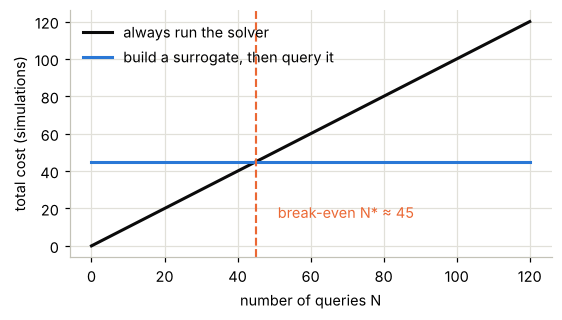

In [2]:
c_sim, D, C_train, c_inf = 1.0, 40, 5.0, 1e-4      # costs in units of one simulation
N_star = (D * c_sim + C_train) / (c_sim - c_inf)
N = np.linspace(0, 120, 400)
fig, ax = plt.subplots(figsize=(5.2, 3.0))
ax.plot(N, N * c_sim, color=INK, lw=2, label="always run the solver")
ax.plot(N, D * c_sim + C_train + N * c_inf, color=BLUE, lw=2, label="build a surrogate, then query it")
ax.axvline(N_star, color=ORANGE, ls="--", lw=1.4)
ax.annotate(f"break-even N* ≈ {N_star:.0f}", (N_star, 10), xytext=(N_star + 6, 15), color=ORANGE)
ax.set_xlabel("number of queries N"); ax.set_ylabel("total cost (simulations)")
ax.legend(loc="upper left"); save(fig, "fig-breakeven")
REF["breakeven"] = dict(c_sim=c_sim, D=D, C_train=C_train, c_inf=c_inf, N_star=round(N_star, 2))
print(REF["breakeven"])

## 2. Sampling the design space

A design of experiments (DOE) chooses the $D$ training inputs. We compare four 16-point designs in
$[0,1]^2$: a $4\times4$ grid, plain random sampling, a Latin hypercube (LHS, McKay et al. 1979) and a
*maximin* Latin hypercube (best of 500 LHS by smallest pairwise distance, Morris & Mitchell 1995).

Two diagnostics: the **minimum pairwise distance** $d_\text{min}$ (bigger = better spread) and the
**centred $L_2$ discrepancy** (smaller = closer to uniform). We also count distinct levels per axis:
if one input turns out not to matter, a grid collapses to 4 distinct points, an LHS keeps 16.

grid 4x4         {'min_dist': 0.25, 'cd2': 0.0114, 'levels_x1': 4}
random           {'min_dist': 0.092, 'cd2': 0.0105, 'levels_x1': 16}
Latin hypercube  {'min_dist': 0.062, 'cd2': 0.0027, 'levels_x1': 16}
maximin LHS      {'min_dist': 0.157, 'cd2': 0.003, 'levels_x1': 16}


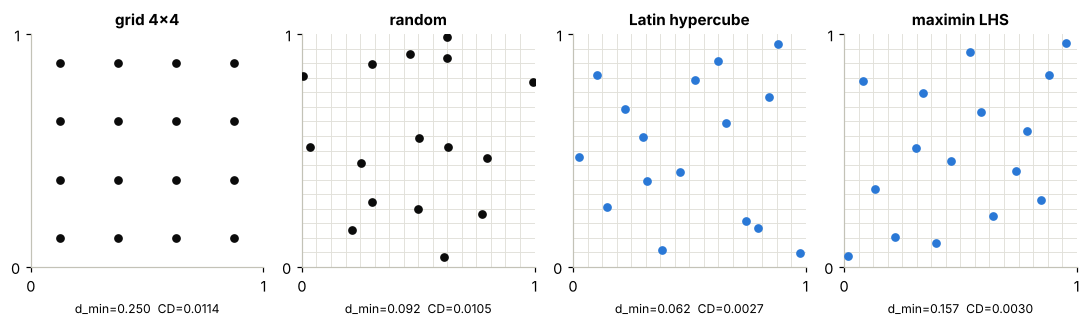

In [3]:
def lhs(n, d, rng):
    "Latin hypercube: one point per row and per column of an n x n grid of strata."
    cols = [(rng.permutation(n) + rng.random(n)) / n for _ in range(d)]
    return np.column_stack(cols)

def min_dist(P):
    diff = P[:, None, :] - P[None, :, :]
    d = np.sqrt((diff ** 2).sum(-1)); d[np.diag_indices(len(P))] = np.inf
    return float(d.min())

def maximin_lhs(n, d, rng, tries=500):
    best, best_d = None, -1
    for _ in range(tries):
        P = lhs(n, d, rng); m = min_dist(P)
        if m > best_d: best, best_d = P, m
    return best

rng = np.random.default_rng(7)
n = 16
g = (np.arange(4) + 0.5) / 4
designs = {
    "grid 4x4": np.array([(a, b) for a in g for b in g]),
    "random": rng.random((n, 2)),
    "Latin hypercube": lhs(n, 2, rng),
    "maximin LHS": maximin_lhs(n, 2, rng),
}
REF["doe"] = {}
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, (name, P) in zip(axes, designs.items()):
    dm, cd = min_dist(P), float(qmc.discrepancy(P, method="CD"))
    levels = len(np.unique(np.round(P[:, 0], 9)))
    REF["doe"][name] = dict(min_dist=round(dm, 3), cd2=round(cd, 4), levels_x1=levels)
    for k in range(1, n):
        if name != "grid 4x4":
            ax.axvline(k / n, color=GRID, lw=0.6); ax.axhline(k / n, color=GRID, lw=0.6)
    ax.scatter(P[:, 0], P[:, 1], s=22, color=BLUE if "LHS" in name or "Latin" in name else INK, zorder=3)
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xticks=[0, 1], yticks=[0, 1], title=name)
    ax.grid(False)
    ax.set_xlabel(f"d_min={dm:.3f}  CD={cd:.4f}", fontsize=8)
save(fig, "fig-doe")
for k, v in REF["doe"].items(): print(f"{k:16s} {v}")

**Curse of dimensionality.** A full-factorial grid with $L$ levels in $d$ dimensions needs $L^d$ runs:
3 levels in 10 inputs is already 59 049 simulations. LHS sizes are free ($D$ is chosen, not imposed),
which is why space-filling designs are the default for computer experiments (Sacks et al. 1989).

In [4]:
for d in (2, 5, 10, 20):
    print(f"d={d:2d}: 3-level grid = {3**d:>14,d} runs   (LHS: any D you can afford)")

d= 2: 3-level grid =              9 runs   (LHS: any D you can afford)
d= 5: 3-level grid =            243 runs   (LHS: any D you can afford)
d=10: 3-level grid =         59,049 runs   (LHS: any D you can afford)
d=20: 3-level grid =  3,486,784,401 runs   (LHS: any D you can afford)


## 3. Fitting a response surface, and testing it honestly

A polynomial response surface $\hat y(x) = \sum_{k=0}^{p} \beta_k \phi_k(x)$ is fitted by least squares:
$\hat\beta = \arg\min \lVert \Phi\beta - y\rVert^2$, i.e. $\Phi^\top\Phi\,\hat\beta = \Phi^\top y$.
We use Legendre polynomials on $[-1,1]$ (better conditioned than monomials).

Data: 15 noisy observations of the Forrester function, $\sigma_\varepsilon = 1$. Increasing the degree
always lowers the **training** error; only data the fit has not seen can tell us when to stop.
We compare training RMSE, 5-fold cross-validation RMSE and the true test RMSE on 1000 points.

{'n_train': 15, 'sigma': 1.0, 'best_degree_cv': 4, 'best_degree_test': 7, 'train_rmse_deg12': 0.222, 'test_rmse_deg12': 43.76, 'cv_rmse_best': 1.907, 'test_rmse_best': 1.404, 'rel_l2_best': 0.313, 'r2_best': 0.901, 'max_err_best': 8.296}


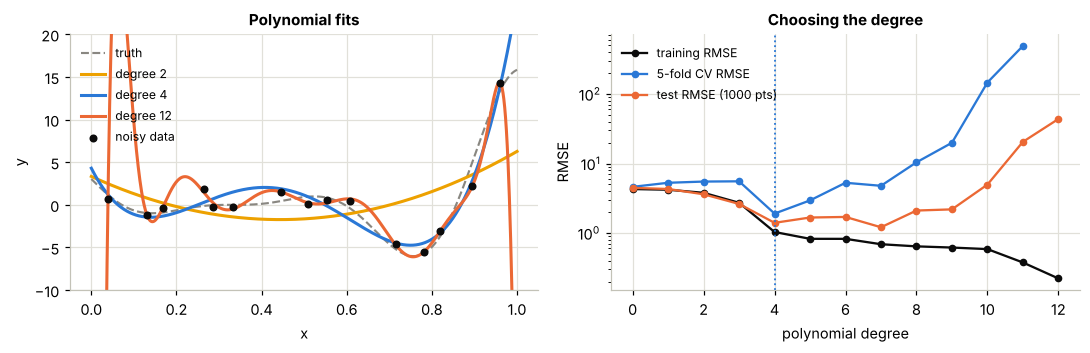

In [5]:
rng = np.random.default_rng(3)
n_tr, sigma = 15, 1.0
x_tr = np.sort(lhs(n_tr, 1, rng)[:, 0])
y_tr = forrester(x_tr) + sigma * rng.standard_normal(n_tr)
x_te = np.linspace(0, 1, 1000); y_te = forrester(x_te)

def poly_fit(x, y, deg):
    return np.polynomial.legendre.legfit(2 * x - 1, y, deg)
def poly_eval(c, x):
    return np.polynomial.legendre.legval(2 * x - 1, c)

def kfold_rmse(x, y, deg, k=5, seed=0):
    idx = np.random.default_rng(seed).permutation(len(x)); folds = np.array_split(idx, k)
    sq = []
    for f in folds:
        tr = np.setdiff1d(idx, f)
        if len(tr) <= deg:            # under-determined: not a valid fit
            return np.inf
        c = poly_fit(x[tr], y[tr], deg); sq.append((poly_eval(c, x[f]) - y[f]) ** 2)
    return float(np.sqrt(np.mean(np.concatenate(sq))))

degs = np.arange(0, 13)
train_e = [rmse(y_tr, poly_eval(poly_fit(x_tr, y_tr, d), x_tr)) for d in degs]
cv_e    = [kfold_rmse(x_tr, y_tr, d) for d in degs]
test_e  = [rmse(y_te, poly_eval(poly_fit(x_tr, y_tr, d), x_te)) for d in degs]
best_cv, best_test = int(degs[np.argmin(cv_e)]), int(degs[np.argmin(test_e)])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.3))
a1.plot(x_te, y_te, color=MUTED, ls="--", lw=1.4, label="truth")
for d, col in [(2, YELLOW), (best_cv, BLUE), (12, ORANGE)]:
    a1.plot(x_te, poly_eval(poly_fit(x_tr, y_tr, d), x_te), color=col, lw=2, label=f"degree {d}")
a1.scatter(x_tr, y_tr, color=INK, s=18, zorder=3, label="noisy data")
a1.set(ylim=(-10, 20), xlabel="x", ylabel="y", title="Polynomial fits")
a1.legend(fontsize=8, loc="upper left")
a2.semilogy(degs, train_e, "o-", color=INK, ms=4, label="training RMSE")
a2.semilogy(degs, cv_e, "o-", color=BLUE, ms=4, label="5-fold CV RMSE")
a2.semilogy(degs, test_e, "o-", color=ORANGE, ms=4, label="test RMSE (1000 pts)")
a2.axvline(best_cv, color=BLUE, ls=":", lw=1.2)
a2.set(xlabel="polynomial degree", ylabel="RMSE", title="Choosing the degree")
a2.legend(fontsize=8); save(fig, "fig-poly-cv")

c_best = poly_fit(x_tr, y_tr, best_cv); y_best = poly_eval(c_best, x_te)
REF["poly"] = dict(n_train=n_tr, sigma=sigma, best_degree_cv=best_cv, best_degree_test=best_test,
                   train_rmse_deg12=round(train_e[12], 3), test_rmse_deg12=round(test_e[12], 2),
                   cv_rmse_best=round(cv_e[best_cv], 3), test_rmse_best=round(test_e[best_cv], 3),
                   rel_l2_best=round(rel_l2(y_te, y_best), 3), r2_best=round(r2(y_te, y_best), 3),
                   max_err_best=round(max_err(y_te, y_best), 3))
print(REF["poly"])

**Error metrics.** RMSE is in the units of $y$; the relative $L_2$ error
$\lVert y-\hat y\rVert/\lVert y\rVert$ is scale-free; $R^2 = 1 - \sum(y-\hat y)^2/\sum(y-\bar y)^2$
compares against predicting the mean; the maximum error catches the one bad region that averages hide.
Report more than one.

**Split by run, not by point.** When each simulation produces a whole field, all points of one run
are strongly correlated. Put entire runs in either the training or the test set — never both —
or the test error will look far better than it is.

## 4. Gaussian processes

A Gaussian process (GP) puts a prior on functions, $y \sim \mathcal{GP}(0, k)$, with e.g. the
squared-exponential kernel $k(x,x') = \sigma_f^2 \exp(-\lVert x-x'\rVert^2/2\ell^2)$, plus a noise
term $\sigma_n^2$. Conditioning on the data gives a closed-form predictive mean **and variance**:

$$\bar y_* = k_*^\top (K+\sigma_n^2 I)^{-1} y,\qquad \operatorname{var}(y_*) = k_{**} - k_*^\top (K+\sigma_n^2 I)^{-1} k_* .$$

Hyperparameters $(\sigma_f, \ell, \sigma_n)$ are fitted by maximizing the log marginal likelihood.
Cost: $O(D^3)$ time and $O(D^2)$ memory, fine for hundreds to a few thousand runs.

{'kernel': '2.5**2 * RBF(length_scale=0.176) + WhiteKernel(noise_level=0.0757)', 'test_rmse': 0.624, 'rel_l2': 0.139, 'frac_truth_in_2sigma': 1.0}


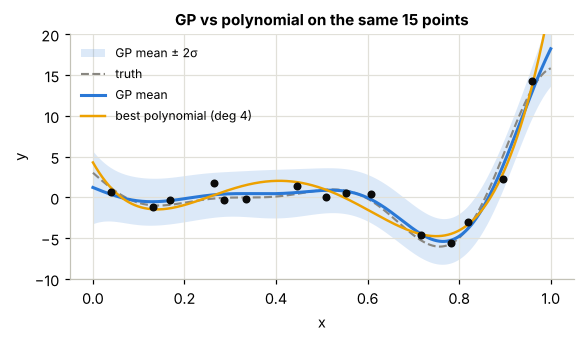

In [6]:
kernel = ConstantKernel(10.0, (1e-2, 1e3)) * RBF(0.2, (1e-2, 10.0)) + WhiteKernel(1.0, (1e-4, 10.0))
gp = GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp.fit(x_tr[:, None], y_tr)
mu, sd = gp.predict(x_te[:, None], return_std=True)
fig, ax = plt.subplots(figsize=(5.4, 3.2))
ax.fill_between(x_te, mu - 2 * sd, mu + 2 * sd, color=BLUE, alpha=0.16, lw=0, label="GP mean ± 2σ")
ax.plot(x_te, y_te, color=MUTED, ls="--", lw=1.4, label="truth")
ax.plot(x_te, mu, color=BLUE, lw=2, label="GP mean")
ax.plot(x_te, y_best, color=YELLOW, lw=1.6, label=f"best polynomial (deg {best_cv})")
ax.scatter(x_tr, y_tr, color=INK, s=18, zorder=3)
ax.set(xlabel="x", ylabel="y", ylim=(-10, 20), title="GP vs polynomial on the same 15 points")
ax.legend(fontsize=8, loc="upper left"); save(fig, "fig-gp")
inside = np.mean(np.abs(y_te - mu) <= 2 * sd)
REF["gp"] = dict(kernel=str(gp.kernel_), test_rmse=round(rmse(y_te, mu), 3),
                 rel_l2=round(rel_l2(y_te, mu), 3), frac_truth_in_2sigma=round(float(inside), 3))
print(REF["gp"])

## 5. Compressing fields: proper orthogonal decomposition

When a simulation returns a whole field $u(x;\mu)$ sampled at $M$ points, we stack $N$ training
snapshots (minus their mean $\bar u$) as columns of $Y\in\mathbb{R}^{M\times N}$ and take its SVD
$Y = U\Sigma V^\top$. The first $K$ left singular vectors $\phi_k$ are the POD modes:

$$u(x;\mu) \approx \bar u(x) + \sum_{k=1}^{K} a_k(\mu)\,\phi_k(x),\qquad a_k = \phi_k^\top (u-\bar u).$$

By the Eckart–Young theorem no other $K$-dimensional basis has smaller projection error on the
snapshots; the fraction of "energy" kept is $\sum_{k\le K}\sigma_k^2/\sum_k\sigma_k^2$.
A surrogate then only needs to learn the $K$ coefficients $a_k(\mu)$ — here with one GP per coefficient.

We contrast two one-parameter families on $x\in[0,1]$, $M=200$ points, 40 training snapshots:

* **diffusion** — a square pulse spreading by the heat equation, $\mu = t$;
* **transport** — a narrow Gaussian bump moving along the domain, $\mu = c$ (its position).

diffusion {'K_99': 2, 'K_999': 3, 'energy_mode1': 0.9708, 'proj_err_K5': 0.0003, 'proj_err_K10': 0.0}
transport {'K_99': 14, 'K_999': 19, 'energy_mode1': 0.1624, 'proj_err_K5': 0.5039, 'proj_err_K10': 0.2241}


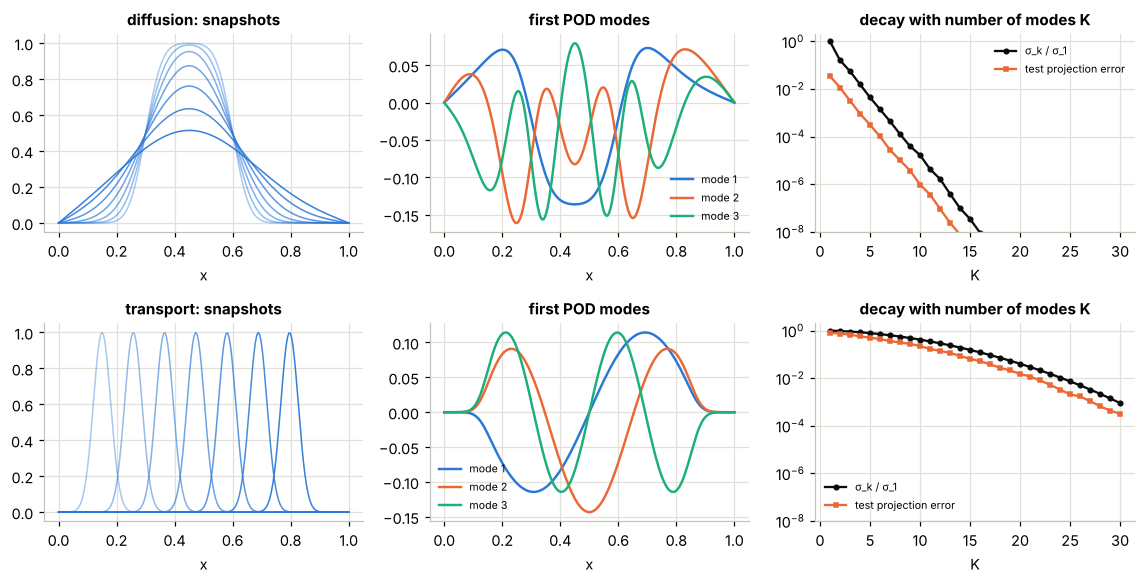

In [7]:
M = 200
xf = np.linspace(0, 1, M)
kk = np.arange(1, 301)
bk = 2 / (kk * np.pi) * (np.cos(kk * np.pi * 0.3) - np.cos(kk * np.pi * 0.6))   # sine coefficients of the pulse on [0.3, 0.6]
S_k = np.sin(np.outer(xf, kk) * np.pi)

def diffusion(t):  return S_k @ (bk * np.exp(-(kk * np.pi) ** 2 * t))
def transport(c):  return np.exp(-(xf - c) ** 2 / (2 * 0.03 ** 2))

fam = {
    "diffusion": dict(f=diffusion, train=np.geomspace(1e-3, 3e-2, 40),
                      test=np.geomspace(1e-3, 3e-2, 400)[np.random.default_rng(1).choice(400, 12, replace=False)],
                      feat=np.log),
    "transport": dict(f=transport, train=np.linspace(0.15, 0.85, 40),
                      test=np.random.default_rng(2).uniform(0.16, 0.84, 12), feat=lambda c: c),
}
for name, F in fam.items():
    Ytr = np.column_stack([F["f"](m) for m in F["train"]])
    Yte = np.column_stack([F["f"](m) for m in F["test"]])
    ubar = Ytr.mean(1, keepdims=True)
    U, s, Vt = np.linalg.svd(Ytr - ubar, full_matrices=False)
    energy = np.cumsum(s ** 2) / np.sum(s ** 2)
    proj_err = []
    for K in range(1, 31):
        A = U[:, :K].T @ (Yte - ubar)
        proj_err.append(rel_l2(Yte, ubar + U[:, :K] @ A))
    F.update(Ytr=Ytr, Yte=Yte, ubar=ubar, U=U, s=s, energy=energy, proj_err=np.array(proj_err))

fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.4))
for row, (name, F) in enumerate(fam.items()):
    a = axes[row, 0]
    for j in range(0, 40, 6): a.plot(xf, F["Ytr"][:, j], color=BLUE, lw=1, alpha=0.4 + 0.6 * j / 40)
    a.set(title=f"{name}: snapshots", xlabel="x")
    a = axes[row, 1]
    for k, col in zip(range(3), [BLUE, ORANGE, AQUA]): a.plot(xf, F["U"][:, k], color=col, lw=1.6, label=f"mode {k+1}")
    a.set(title="first POD modes", xlabel="x"); a.legend(fontsize=7)
    a = axes[row, 2]
    a.semilogy(np.arange(1, 31), F["s"][:30] / F["s"][0], "o-", ms=3, color=INK, label="σ_k / σ_1")
    a.semilogy(np.arange(1, 31), F["proj_err"], "s-", ms=3, color=ORANGE, label="test projection error")
    a.set(title="decay with number of modes K", xlabel="K", ylim=(1e-8, 2)); a.legend(fontsize=7)
save(fig, "fig-pod")

REF["pod"] = {}
for name, F in fam.items():
    K99 = int(np.searchsorted(F["energy"], 0.99) + 1); K999 = int(np.searchsorted(F["energy"], 0.999) + 1)
    REF["pod"][name] = dict(K_99=K99, K_999=K999, energy_mode1=round(float(F["energy"][0]), 4),
                            proj_err_K5=round(float(F["proj_err"][4]), 4), proj_err_K10=round(float(F["proj_err"][9]), 4))
    print(name, REF["pod"][name])

**POD + GP.** For each family keep $K$ modes and fit one GP per coefficient $a_k(\mu)$
(input $\log t$ for diffusion, $c$ for transport). Predict the 12 test fields and compare with
(i) the mean field alone and (ii) the best possible $K$-mode projection (a lower bound).

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 13 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 19 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 21 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 17 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/

diffusion {'K': 6, 'err_pod_gp': 0.0001, 'err_mean_field': 0.2376, 'err_projection': 0.0001}


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 24 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 21 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 15 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 23 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 28 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 19 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 23 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 28 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 16 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/

transport {'K': 10, 'err_pod_gp': 0.2241, 'err_mean_field': 0.9208, 'err_projection': 0.2241}


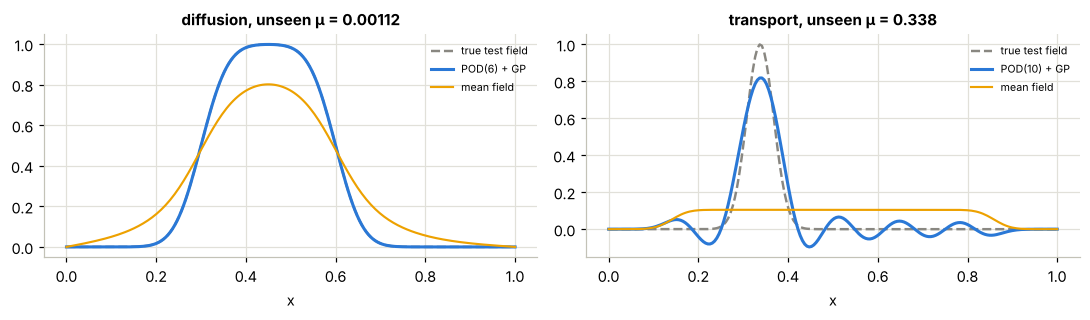

In [8]:
def pod_gp(F, K):
    A_tr = F["U"][:, :K].T @ (F["Ytr"] - F["ubar"])
    z_tr, z_te = F["feat"](F["train"])[:, None], F["feat"](F["test"])[:, None]
    A_hat = []
    for k in range(K):
        kern = ConstantKernel(1.0, (1e-3, 1e3)) * RBF(0.5, (1e-3, 1e2)) + WhiteKernel(1e-6, (1e-10, 1e-2))
        g = GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=3, random_state=0).fit(z_tr, A_tr[k])
        A_hat.append(g.predict(z_te))
    return F["ubar"] + F["U"][:, :K] @ np.array(A_hat)

REF["pod_gp"] = {}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.0))
for ax, (name, F) in zip(axes, fam.items()):
    K = 6 if name == "diffusion" else 10
    Yhat = pod_gp(F, K)
    j = 0
    ax.plot(xf, F["Yte"][:, j], color=MUTED, ls="--", lw=1.6, label="true test field")
    ax.plot(xf, Yhat[:, j], color=BLUE, lw=2, label=f"POD({K}) + GP")
    ax.plot(xf, F["ubar"][:, 0], color=YELLOW, lw=1.4, label="mean field")
    ax.set(title=f"{name}, unseen μ = {F['test'][j]:.3g}", xlabel="x"); ax.legend(fontsize=7)
    REF["pod_gp"][name] = dict(K=K, err_pod_gp=round(rel_l2(F["Yte"], Yhat), 4),
                               err_mean_field=round(rel_l2(F["Yte"], np.repeat(F["ubar"], 12, 1)), 4),
                               err_projection=round(float(F["proj_err"][K - 1]), 4))
    print(name, REF["pod_gp"][name])
save(fig, "fig-pod-gp")

Diffusion smooths everything out: a handful of modes captures the family and the coefficients vary
smoothly with $\log t$, so POD + GP works very well. A moving, sharp feature is the classic hard case
for any *linear* basis: each position needs its own modes, the singular values decay slowly
(the family has a large Kolmogorov $n$-width), and nonlinear methods (shifted/registered POD,
autoencoders, neural operators) start to pay off.

## 6. Neural-network surrogates

A multilayer perceptron (MLP) with tanh hidden layers,
$h^{(l)} = \tanh(W^{(l)}h^{(l-1)} + b^{(l)})$ and a linear output, is trained by minimizing the mean
squared error with gradient-based steps $w \leftarrow w - \eta\,\nabla_w L$. The gradient comes from
**backpropagation** — the chain rule applied layer by layer from the output back to the input.
Below it is written out by hand in NumPy, checked against finite differences, and trained with Adam.

In [9]:
class MLP:
    def __init__(self, sizes, seed=0):
        r = np.random.default_rng(seed)
        self.W = [r.standard_normal((o, i)) * np.sqrt(1.0 / i) for i, o in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(o) for o in sizes[1:]]
        self.m = [np.zeros_like(p) for p in self.W + self.b]; self.v = [np.zeros_like(p) for p in self.W + self.b]; self.t = 0

    def forward(self, X):                       # X: (n, d_in)
        hs = [X]
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            z = hs[-1] @ W.T + b
            hs.append(z if l == len(self.W) - 1 else np.tanh(z))
        return hs

    def loss_grad(self, X, y):
        hs = self.forward(X); n = len(X)
        err = hs[-1][:, 0] - y
        loss = np.mean(err ** 2)
        delta = (2 / n) * err[:, None]          # dL/d(output)
        gW, gb = [None] * len(self.W), [None] * len(self.b)
        for l in reversed(range(len(self.W))):
            gW[l] = delta.T @ hs[l]; gb[l] = delta.sum(0)
            if l > 0:
                delta = (delta @ self.W[l]) * (1 - hs[l] ** 2)    # chain rule through tanh
        return loss, gW, gb

    def adam_step(self, gW, gb, lr=1e-2, b1=0.9, b2=0.999, eps=1e-8):
        self.t += 1
        for i, (p, g) in enumerate(zip(self.W + self.b, gW + gb)):
            self.m[i] = b1 * self.m[i] + (1 - b1) * g
            self.v[i] = b2 * self.v[i] + (1 - b2) * g * g
            p -= lr * (self.m[i] / (1 - b1 ** self.t)) / (np.sqrt(self.v[i] / (1 - b2 ** self.t)) + eps)

    def predict(self, X): return self.forward(X)[-1][:, 0]

# gradient check: backprop vs central finite differences on a few weights
net = MLP([1, 8, 8, 1], seed=1); Xc = np.linspace(-1, 1, 7)[:, None]; yc = np.sin(3 * Xc[:, 0])
_, gW, _ = net.loss_grad(Xc, yc); h = 1e-6; rels = []
for (l, i, j) in [(0, 3, 0), (1, 2, 5), (2, 0, 4)]:
    w0 = net.W[l][i, j]
    net.W[l][i, j] = w0 + h; lp = net.loss_grad(Xc, yc)[0]
    net.W[l][i, j] = w0 - h; lm = net.loss_grad(Xc, yc)[0]
    net.W[l][i, j] = w0
    fd = (lp - lm) / (2 * h); rels.append(abs(fd - gW[l][i, j]) / max(abs(fd), 1e-12))
REF["gradcheck_max_rel_err"] = float(f"{max(rels):.1e}")
print("max relative error backprop vs finite differences:", max(rels))

max relative error backprop vs finite differences: 2.731485222777425e-09


**Normalize inputs and outputs** with statistics of the training set only. Engineering inputs come in
physical units: here we pretend $x$ is a position given in percent of span, $x_\text{phys} = 100x \in [0, 100]$,
and the outputs range over about $[-6, 16]$. We train the same network on raw and on standardized
data with plain full-batch gradient descent, holding out 4 of the 15 points as a validation set
(used for early stopping), and compare with the GP of Part 4 on the dense test grid.

{'params': 1153, 'early_stop_epoch_norm': 2535, 'early_stop_epoch_raw': 1657, 'test_rmse_norm': 0.75, 'test_rmse_raw': 4.484, 'test_rmse_gp': 0.624, 'seconds': 2.1}


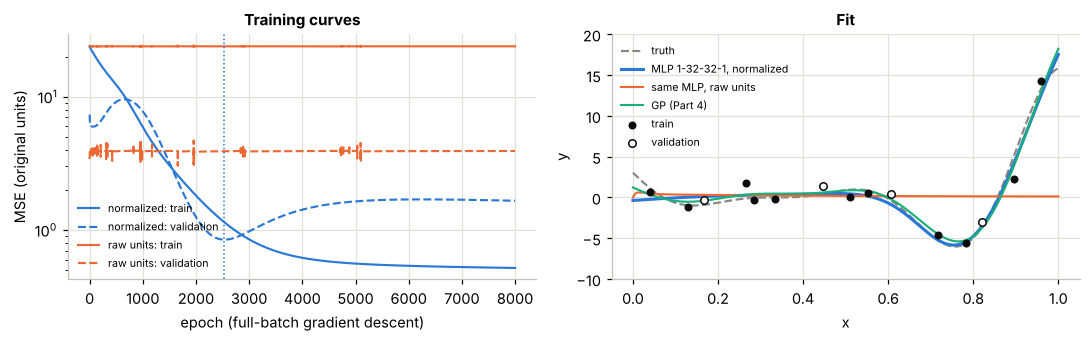

In [10]:
rng = np.random.default_rng(11)
perm = rng.permutation(n_tr); va, tr = perm[:4], perm[4:]
xm, xs = x_tr[tr].mean(), x_tr[tr].std(); ym, ys = y_tr[tr].mean(), y_tr[tr].std()

def train(normalize, opt="gd", epochs=None, lr=None, seed=0):
    # opt='gd': plain full-batch gradient descent w <- w - lr * grad (lr 0.01, 8000 epochs)
    # opt='adam': Adam with cosine learning-rate decay (lr 1e-2, 4000 epochs)
    epochs = epochs or (8000 if opt == "gd" else 4000)
    net = MLP([1, 32, 32, 1], seed=seed)
    nx = (lambda x: (x - xm) / xs) if normalize else (lambda x: 100 * x)   # raw = physical units
    ny, iy = ((lambda y: (y - ym) / ys), (lambda z: z * ys + ym)) if normalize else ((lambda y: y), (lambda z: z))
    Xt, yt, Xv = nx(x_tr[tr])[:, None], ny(y_tr[tr]), nx(x_tr[va])[:, None]
    hist, best = [], (np.inf, None, 0)
    for ep in range(epochs):
        loss, gW, gb = net.loss_grad(Xt, yt)
        if opt == "adam":
            net.adam_step(gW, gb, (lr or 1e-2) * 0.5 * (1 + np.cos(np.pi * ep / epochs)))
        else:
            for p_, g_ in zip(net.W + net.b, gW + gb): p_ -= (lr or 0.01) * g_
        val = np.mean((iy(net.predict(Xv)) - y_tr[va]) ** 2)
        hist.append((np.mean((iy(net.predict(Xt)) - y_tr[tr]) ** 2), val))
        if val < best[0]: best = (val, [w.copy() for w in net.W] + [b.copy() for b in net.b], ep)
    k = len(net.W); net.W, net.b = best[1][:k], best[1][k:]
    return net, np.array(hist), best[2], (lambda x: iy(net.predict(nx(x)[:, None])))

t0 = time.time()
net_n, hist_n, ep_n, f_n = train(True)
net_r, hist_r, ep_r, f_r = train(False)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
a1.semilogy(hist_n[:, 0], color=BLUE, lw=1.4, label="normalized: train")
a1.semilogy(hist_n[:, 1], color=BLUE, lw=1.4, ls="--", label="normalized: validation")
a1.semilogy(hist_r[:, 0], color=ORANGE, lw=1.4, label="raw units: train")
a1.semilogy(hist_r[:, 1], color=ORANGE, lw=1.4, ls="--", label="raw units: validation")
a1.axvline(ep_n, color=BLUE, ls=":", lw=1)
a1.set(xlabel="epoch (full-batch gradient descent)", ylabel="MSE (original units)", title="Training curves"); a1.legend(fontsize=7)
a2.plot(x_te, y_te, color=MUTED, ls="--", lw=1.4, label="truth")
a2.plot(x_te, f_n(x_te), color=BLUE, lw=2, label="MLP 1-32-32-1, normalized")
a2.plot(x_te, f_r(x_te), color=ORANGE, lw=1.4, label="same MLP, raw units")
a2.plot(x_te, mu, color=AQUA, lw=1.4, label="GP (Part 4)")
a2.scatter(x_tr[tr], y_tr[tr], color=INK, s=18, zorder=3, label="train")
a2.scatter(x_tr[va], y_tr[va], facecolor="white", edgecolor=INK, s=24, zorder=3, label="validation")
a2.set(xlabel="x", ylabel="y", ylim=(-10, 20), title="Fit"); a2.legend(fontsize=7, loc="upper left")
save(fig, "fig-nn")
n_params = sum(w.size for w in net_n.W) + sum(b.size for b in net_n.b)
REF["nn"] = dict(params=int(n_params), early_stop_epoch_norm=int(ep_n), early_stop_epoch_raw=int(ep_r),
                 test_rmse_norm=round(rmse(y_te, f_n(x_te)), 3), test_rmse_raw=round(rmse(y_te, f_r(x_te)), 3),
                 test_rmse_gp=REF["gp"]["test_rmse"], seconds=round(time.time() - t0, 1))
print(REF["nn"])

Is that a fluke of one random initialization? Repeat over 8 seeds, for plain gradient descent and for
Adam (which rescales every parameter's step by a running estimate of its gradient magnitude):

In [11]:
study = {}
for opt in ("gd", "adam"):
    for normalize in (True, False):
        errs = [rmse(y_te, train(normalize, opt=opt, seed=sd)[3](x_te)) for sd in range(8)]
        study[f"{opt}_{'norm' if normalize else 'raw'}"] = round(float(np.median(errs)), 3)
REF["nn_seeds_median_test_rmse"] = study
print(study)

{'gd_norm': 0.819, 'gd_raw': 4.481, 'adam_norm': 1.227, 'adam_raw': 0.969}


With plain gradient descent, raw units are a disaster: the gradient with respect to the first-layer
weights is multiplied by $x_\text{phys}\sim 100$, so the step size that keeps those weights stable is far
too small for the rest of the network, and many tanh units sit saturated (derivative $1-\tanh^2\approx 0$).
Standardizing puts every unit in its sensitive range and one learning rate suits all layers.
Adam largely hides the problem on this example because it normalizes each parameter's step — one
reason it is the default optimizer — but normalizing your data stays the safe habit (and matters for
weight decay, initialization and multi-output losses alike).

Note also that with 11 training points and 1 153 weights the network can interpolate the noise, which
is why validation-based early stopping (or weight decay) is not optional. On small, smooth,
low-dimensional problems a GP is usually the stronger baseline; networks earn their place when there
are many runs and whole fields to predict (see the article's frontier section).

## 7. Trust, uncertainty and design loops

### 7a. Ensembles: disagreement as an uncertainty signal
Train 5 networks from different random initializations on all 15 points and look at their spread,
including outside the training interval $[0,1]$.

{'mean_sd_inside': 0.38, 'mean_sd_outside': 1.1}


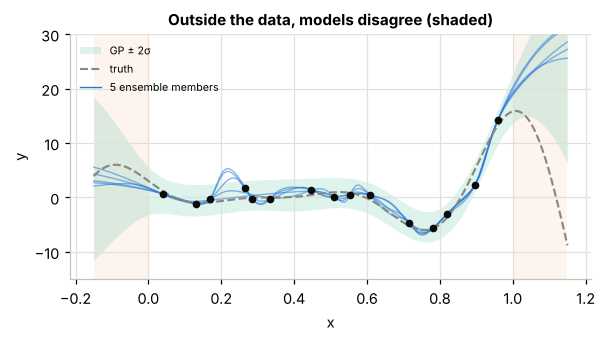

In [12]:
xm, xs = x_tr.mean(), x_tr.std(); ym, ys = y_tr.mean(), y_tr.std()
x_ext = np.linspace(-0.15, 1.15, 600)
preds = []
for seed in range(5):
    net = MLP([1, 32, 32, 1], seed=seed)
    Xt, yt = ((x_tr - xm) / xs)[:, None], (y_tr - ym) / ys
    for ep in range(2500):
        _, gW, gb = net.loss_grad(Xt, yt); net.adam_step(gW, gb, 1e-2)
    preds.append(net.predict(((x_ext - xm) / xs)[:, None]) * ys + ym)
preds = np.array(preds); ens_mu, ens_sd = preds.mean(0), preds.std(0)
mu_e, sd_e = gp.predict(x_ext[:, None], return_std=True)
fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.axvspan(-0.15, 0, color=ORANGE, alpha=0.07, lw=0); ax.axvspan(1, 1.15, color=ORANGE, alpha=0.07, lw=0)
for p in preds: ax.plot(x_ext, p, color=BLUE, lw=0.9, alpha=0.55)
ax.fill_between(x_ext, mu_e - 2 * sd_e, mu_e + 2 * sd_e, color=AQUA, alpha=0.15, lw=0, label="GP ± 2σ")
ax.plot(x_ext, forrester(x_ext), color=MUTED, ls="--", lw=1.4, label="truth")
ax.plot([], [], color=BLUE, lw=0.9, label="5 ensemble members")
ax.scatter(x_tr, y_tr, color=INK, s=16, zorder=3)
ax.set(xlabel="x", ylabel="y", ylim=(-15, 30), title="Outside the data, models disagree (shaded)")
ax.legend(fontsize=7, loc="upper left"); save(fig, "fig-ensemble")
inside = (x_ext >= 0) & (x_ext <= 1)
REF["ensemble"] = dict(mean_sd_inside=round(float(ens_sd[inside].mean()), 2), mean_sd_outside=round(float(ens_sd[~inside].mean()), 2))
print(REF["ensemble"])

### 7b. Split conformal prediction: intervals with a guarantee
Fit any model on a training set; compute absolute residuals $r_i = |y_i - \hat y(x_i)|$ on a separate
**calibration** set of size $n$; let $\hat q$ be the $\lceil (n+1)(1-\alpha)\rceil$-th smallest residual.
Then for a new exchangeable point, $P\big(y \in [\hat y(x)-\hat q,\ \hat y(x)+\hat q]\big) \ge 1-\alpha$ —
whatever the model, as long as calibration and test data come from the same distribution.
A *normalized* score $r_i/\hat\sigma(x_i)$ gives intervals that widen where the model is unsure.

{'alpha': 0.1, 'n_cal': 200, 'q_abs': 2.249, 'coverage_abs': 0.896, 'coverage_norm': 0.879, 'coverage_gp_gaussian': 0.826, 'mean_coverage_300': 0.899}


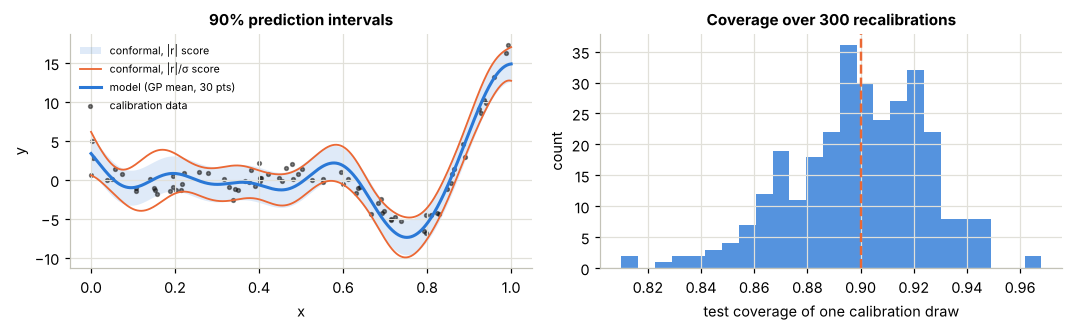

In [13]:
rng = np.random.default_rng(5); alpha = 0.1
def sample(n): x = rng.random(n); return x, forrester(x) + sigma * rng.standard_normal(n)
x_a, y_a = sample(30); x_c, y_c = sample(200); x_t, y_t = sample(5000)
gpc = GaussianProcessRegressor(ConstantKernel(10.0) * RBF(0.2) + WhiteKernel(1.0), normalize_y=True,
                               n_restarts_optimizer=5, random_state=0).fit(x_a[:, None], y_a)
mc, sc = gpc.predict(x_c[:, None], return_std=True); mt, st = gpc.predict(x_t[:, None], return_std=True)
rank = int(np.ceil((len(x_c) + 1) * (1 - alpha)))
q_abs = np.sort(np.abs(y_c - mc))[rank - 1]
q_norm = np.sort(np.abs(y_c - mc) / sc)[rank - 1]
cov_abs = np.mean(np.abs(y_t - mt) <= q_abs)
cov_norm = np.mean(np.abs(y_t - mt) <= q_norm * st)
cov_gp = np.mean(np.abs(y_t - mt) <= norm.ppf(1 - alpha / 2) * st)
# repeat the calibration many times to show the guarantee holds on average
covs = []
for rep in range(300):
    xc2, yc2 = sample(200); xt2, yt2 = sample(500)
    m2 = gpc.predict(xc2[:, None]); q2 = np.sort(np.abs(yc2 - m2))[rank - 1]
    covs.append(np.mean(np.abs(yt2 - gpc.predict(xt2[:, None])) <= q2))
xs_ = np.linspace(0, 1, 400); ms_, ss_ = gpc.predict(xs_[:, None], return_std=True)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.1))
a1.fill_between(xs_, ms_ - q_abs, ms_ + q_abs, color=BLUE, alpha=0.15, lw=0, label=f"conformal, |r| score")
a1.plot(xs_, ms_ - q_norm * ss_, color=ORANGE, lw=1.2); a1.plot(xs_, ms_ + q_norm * ss_, color=ORANGE, lw=1.2, label="conformal, |r|/σ score")
a1.plot(xs_, ms_, color=BLUE, lw=2, label="model (GP mean, 30 pts)")
a1.scatter(x_c[:80], y_c[:80], s=6, color=INK, alpha=0.5, label="calibration data")
a1.set(xlabel="x", ylabel="y", title=f"90% prediction intervals"); a1.legend(fontsize=7, loc="upper left")
a2.hist(covs, bins=25, color=BLUE, alpha=0.8); a2.axvline(1 - alpha, color=ORANGE, lw=1.6, ls="--")
a2.set(xlabel="test coverage of one calibration draw", ylabel="count", title="Coverage over 300 recalibrations")
save(fig, "fig-conformal")
REF["conformal"] = dict(alpha=alpha, n_cal=len(x_c), q_abs=round(float(q_abs), 3),
                        coverage_abs=round(float(cov_abs), 3), coverage_norm=round(float(cov_norm), 3),
                        coverage_gp_gaussian=round(float(cov_gp), 3), mean_coverage_300=round(float(np.mean(covs)), 3))
print(REF["conformal"])

### 7c. Choosing the next simulation
A surrogate with uncertainty can decide where to simulate next. Two common criteria on a GP:

* **uncertainty sampling** — run where $\sigma(x)$ is largest: improves the surrogate *everywhere*;
* **expected improvement** (Jones et al. 1998) — run where $\mathbb{E}[\max(y_\min - y(x), 0)]$ is
  largest: hunts the *minimum*, with $EI = (y_\min-\mu)\Phi(z) + \sigma\phi(z)$, $z=(y_\min-\mu)/\sigma$.

Starting from 3 points on the noise-free Forrester function, we add 8 points with each criterion
(and at random), over 20 random initial designs, and track the global error and the best value found.

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


... (30 outputs left out)

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 12 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 11 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 14 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.

{'uncertainty': {'final_rmse_median': 0.1, 'final_gap_median': 0.3576}, 'EI': {'final_rmse_median': 0.384, 'final_gap_median': 0.0}, 'random': {'final_rmse_median': 0.463, 'final_gap_median': 0.2728}}


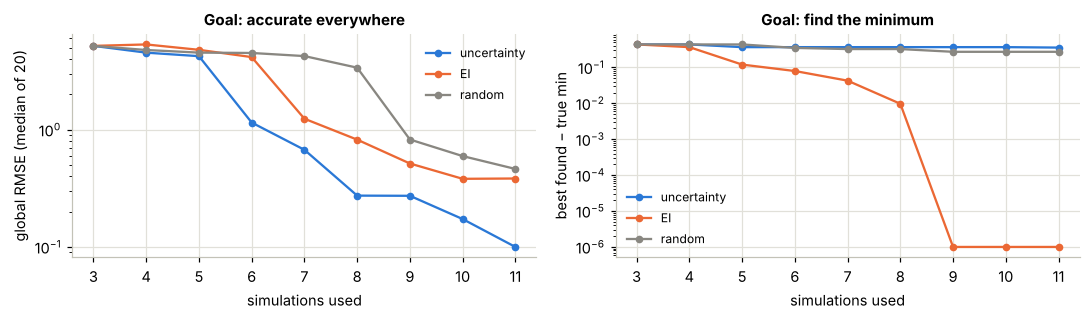

In [14]:
def fit_gp(X, y):
    k = ConstantKernel(10.0, (1e-2, 1e4)) * RBF(0.2, (1e-2, 10.0))
    return GaussianProcessRegressor(k, normalize_y=True, alpha=1e-8, n_restarts_optimizer=3, random_state=0).fit(X[:, None], y)

xc_ = np.linspace(0, 1, 501); f_min = forrester(xc_).min()
def run(strategy, seed, n0=3, iters=8):
    r = np.random.default_rng(seed)
    X = lhs(n0, 1, r)[:, 0]; y = forrester(X); errs, bests = [], []
    for it in range(iters + 1):
        g = fit_gp(X, y); m, s = g.predict(xc_[:, None], return_std=True)
        errs.append(rmse(forrester(xc_), m)); bests.append(y.min() - f_min)
        if it == iters: break
        if strategy == "uncertainty": xn = xc_[np.argmax(s)]
        elif strategy == "EI":
            s_ = np.maximum(s, 1e-12); z = (y.min() - m) / s_
            xn = xc_[np.argmax((y.min() - m) * norm.cdf(z) + s_ * norm.pdf(z))]
        else: xn = r.random()
        X, y = np.append(X, xn), np.append(y, forrester(xn))
    return np.array(errs), np.array(bests)

res = {s: np.array([run(s, seed) for seed in range(20)]) for s in ("uncertainty", "EI", "random")}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.0))
for s, col in [("uncertainty", BLUE), ("EI", ORANGE), ("random", MUTED)]:
    n_runs = 3 + np.arange(9)
    a1.semilogy(n_runs, np.median(res[s][:, 0], 0), "o-", ms=4, color=col, label=s)
    a2.semilogy(n_runs, np.median(res[s][:, 1], 0) + 1e-6, "o-", ms=4, color=col, label=s)
a1.set(xlabel="simulations used", ylabel="global RMSE (median of 20)", title="Goal: accurate everywhere"); a1.legend(fontsize=8)
a2.set(xlabel="simulations used", ylabel="best found − true min", title="Goal: find the minimum"); a2.legend(fontsize=8)
save(fig, "fig-active")
REF["active"] = {s: dict(final_rmse_median=round(float(np.median(res[s][:, 0, -1])), 3),
                         final_gap_median=round(float(np.median(res[s][:, 1, -1])), 4)) for s in res}
print(REF["active"])

Each criterion wins at its own goal — accuracy everywhere versus the location of the minimum.
Decide which question you are asking *before* choosing where to sample. The companion GP/BO article
develops the optimization side (EI, constraints, SEGOMOE) interactively.

### 7d. Beyond this notebook
Field networks (U-Net, MeshGraphNets), neural operators (DeepONet, FNO), transformer surrogates
(Transolver), multi-fidelity and physics-informed training, and pretrained physics models are
discussed in the article's last section, with references.

In [15]:
Path("reference_numbers.json").write_text(json.dumps(REF, indent=2))
print(json.dumps(REF, indent=2))

{
  "breakeven": {
    "c_sim": 1.0,
    "D": 40,
    "C_train": 5.0,
    "c_inf": 0.0001,
    "N_star": 45.0
  },
  "doe": {
    "grid 4x4": {
      "min_dist": 0.25,
      "cd2": 0.0114,
      "levels_x1": 4
    },
    "random": {
      "min_dist": 0.092,
      "cd2": 0.0105,
      "levels_x1": 16
    },
    "Latin hypercube": {
      "min_dist": 0.062,
      "cd2": 0.0027,
      "levels_x1": 16
    },
    "maximin LHS": {
      "min_dist": 0.157,
      "cd2": 0.003,
      "levels_x1": 16
    }
  },
  "poly": {
    "n_train": 15,
    "sigma": 1.0,
    "best_degree_cv": 4,
    "best_degree_test": 7,
    "train_rmse_deg12": 0.222,
    "test_rmse_deg12": 43.76,
    "cv_rmse_best": 1.907,
    "test_rmse_best": 1.404,
    "rel_l2_best": 0.313,
    "r2_best": 0.901,
    "max_err_best": 8.296
  },
  "gp": {
    "kernel": "2.5**2 * RBF(length_scale=0.176) + WhiteKernel(noise_level=0.0757)",
    "test_rmse": 0.624,
    "rel_l2": 0.139,
    "frac_truth_in_2sigma": 1.0
  },
  "pod": {
    "diff